# IM-free wireless mic planner

**[Team name]**: [Member 1], [Member 2], [Member 3], [Member 4]
Qiskit Fall Fest 2026, University of Waterloo

Wireless mics fail in a way that surprises newcomers. When several mics transmit at once, their signals mix and create ghost signals at new frequencies. If a ghost lands on another mic's frequency, that mic crackles. Professionals plan around this with vendor software or a dedicated RF coordinator. This notebook turns the planning rules into a cost function on qubits and searches it with QAOA, behind one plain-English function:

```python
plan_mics(band="470-474 MHz", mics=5, step="250 kHz", spacing="500 kHz", im_guard="250 kHz")
```

The person using it never sees a QUBO, a Hamiltonian, a penalty weight or a mixer.

**What this is not.** QAOA is a heuristic. The demo has 4,368 possible plans, and brute force solves it in about 10 ms. We claim no speed-up. Our point is modelling: the intermodulation rules are three- and four-way interactions, QAOA takes them as they are, and the circuit itself keeps the mic count fixed.

**How to run.** Python 3.10 or newer with the packages in `requirements.txt`, then Run all. Everything runs live on Qiskit's statevector simulator, in under two minutes on our laptop. Nothing is precomputed or loaded from a file. The code lives in the small `micplanner` package next to this notebook.

In [1]:
import time, platform
T0 = time.perf_counter()

import numpy as np
import matplotlib.pyplot as plt
import qiskit
from IPython.display import Markdown, display

from micplanner import plan_mics, engine, cost, quantum, baselines, plots

print("Python", platform.python_version(), "| Qiskit", qiskit.__version__, "| NumPy", np.__version__)

Python 3.14.8 | Qiskit 2.6.1 | NumPy 2.5.4


## 1. The problem in plain words

Every wireless mic transmits on its own carrier frequency. Radio electronics are slightly non-linear, so two carriers $f_1$ and $f_2$ mix and create third-order intermodulation (IM) products at

$$2f_1 - f_2 \qquad \text{and} \qquad 2f_2 - f_1 .$$

Three carriers also create three-tone products such as $f_1 + f_2 - f_3$. These products are weak, but a receiver tuned to the same frequency hears them as noise. Shure's guide notes that "most manufacturers recommend" at least 250 kHz between any third-order product and any carrier [1].

A worked example with two mics:

2 x f1 - f2 = 469.75 MHz
2 x f2 - f1 = 472.00 MHz


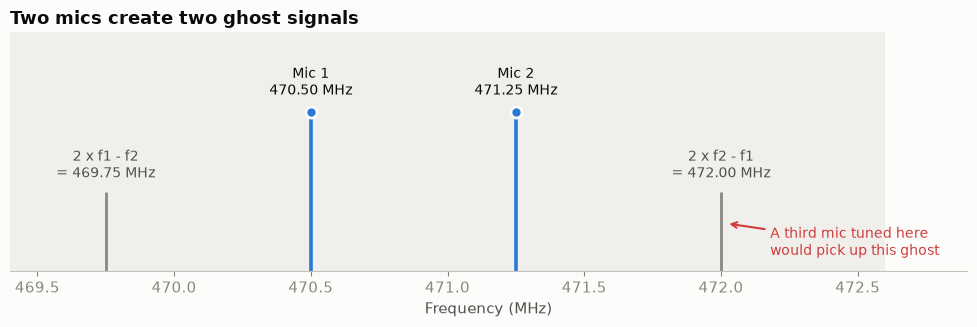

In [2]:
f1, f2 = 470.50, 471.25
print(f"2 x f1 - f2 = {2 * f1 - f2:.2f} MHz")
print(f"2 x f2 - f1 = {2 * f2 - f1:.2f} MHz")
plots.plot_ghost_example();

The count grows fast. $n$ carriers make $n(n-1)$ two-tone and $\binom{n}{2}(n-2)$ three-tone third-order products. Shure's page says three transmitters "may generate six in-band 3rd order" products [1]. Our formula gives nine for three carriers because it counts every two-tone and three-tone product wherever it lands, so the two counts measure different things.

In [3]:
for n in (3, 5, 10, 40):
    c = engine.count_third_order_products(n)
    print(f"{n:>2} mics: {c['two-tone']:>6,} two-tone + {c['three-tone']:>6,} three-tone = {c['total']:>6,}")

 3 mics:      6 two-tone +      3 three-tone =      9
 5 mics:     20 two-tone +     30 three-tone =     50
10 mics:     90 two-tone +    360 three-tone =    450
40 mics:  1,560 two-tone + 29,640 three-tone = 31,200


## 2. Using the tool

**The story.** The Humanities Theatre in Hagey Hall at the University of Waterloo seats up to 721 people [3]. Its technical specifications list three Shure ULD handheld microphones and three Shure ULD wireless body-pack transmitters [4]. Suppose a show uses five of those six Shure channels at once.

The venue pages give no frequency bands or receiver models. So the band below, 470 to 474 MHz, is illustrative, and so is the exclusion further down. A real plan needs the receivers' actual tuning range and a check of local TV channels.

**The rules.** Carriers at least 500 kHz apart (our demo choice, not a vendor rule) and no third-order product within 250 kHz of any carrier [1]. The tool lays a 250 kHz grid over the band. The top edge is left out, so that gives 16 frequencies, which means 16 qubits.

Mic plan: 5 mics, 16 allowed frequencies (16 qubits)
Rules: mics at least 500 kHz apart, no third-order product within 250 kHz of a mic
  Mic 1: 470.000 MHz
  Mic 2: 470.500 MHz
  Mic 3: 471.500 MHz
  Mic 4: 472.750 MHz
  Mic 5: 473.500 MHz
Check: No spacing problems and no third-order product within the guard of any mic.
How it was found: QAOA with 3 layers (CVaR (alpha=0.1) objective), 8,000 samples from Qiskit's StatevectorSampler.
  7.1% of samples were IM-free plans. A plan picked at random is IM-free 0.55% of the time (counted over all 4,368 plans).
  This plan was the most common clean sample (0.5% of samples).
Saved outputs/plan_humanities_theatre.csv


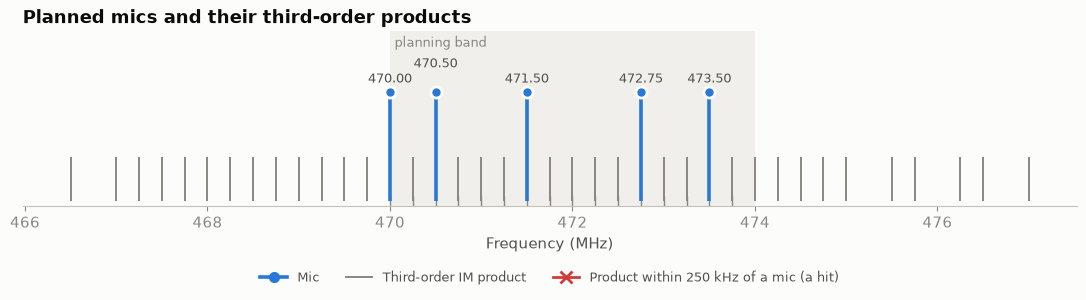

In [4]:
plan = plan_mics(band="470-474 MHz", mics=5, step="250 kHz", spacing="500 kHz",
                 im_guard="250 kHz", csv_path="outputs/plan_humanities_theatre.csv")

The plan is saved as a CSV file that a sound tech can open in a spreadsheet:

In [5]:
print(open(plan.csv_path).read())

mic,frequency_mhz
1,470.000
2,470.500
3,471.500
4,472.750
5,473.500



Now suppose 472.0 to 472.5 MHz is already in use by something else in the building (an illustrative exclusion). One extra argument handles it. Three grid points drop out, so this run uses 13 qubits.

Mic plan: 5 mics, 13 allowed frequencies (13 qubits)
Rules: mics at least 500 kHz apart, no third-order product within 250 kHz of a mic
Kept clear: 472.000 MHz to 472.500 MHz
  Mic 1: 470.000 MHz
  Mic 2: 470.500 MHz
  Mic 3: 471.250 MHz
  Mic 4: 472.750 MHz
  Mic 5: 473.750 MHz
Check: No spacing problems and no third-order product within the guard of any mic.
How it was found: QAOA with 3 layers (CVaR (alpha=0.1) objective), 8,000 samples from Qiskit's StatevectorSampler.
  10.8% of samples were IM-free plans. A plan picked at random is IM-free 0.62% of the time (counted over all 1,287 plans).
  This plan was the most common clean sample (2.2% of samples).
Saved outputs/plan_with_exclusion.csv


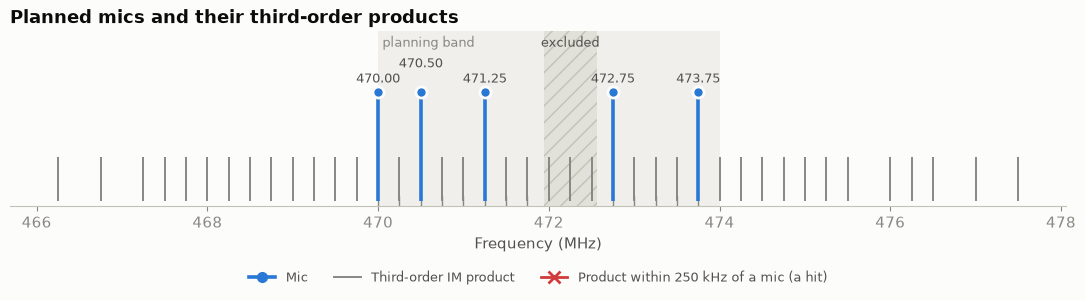

In [6]:
plan_x = plan_mics(band="470-474 MHz", mics=5, step="250 kHz", spacing="500 kHz", im_guard="250 kHz",
                   exclude=["472.0-472.5 MHz"], csv_path="outputs/plan_with_exclusion.csv")

## 3. How it works

**The rules become a cost function.** Each allowed frequency $k$ gets a bit $x_k$, which is 1 when a mic sits there. There are three kinds of conflict:

- $P$: pairs of frequencies closer than the carrier spacing.
- $T$: triples where a two-tone product $2f_k - f_l$ lands within the IM guard of a third mic $f_m$.
- $Q$: quadruples where a three-tone product $f_k + f_l - f_p$ lands within the IM guard of a fourth mic $f_m$.

Each conflicting set counts once:

$$C(x) = \sum_{(k,l)\in P} x_k x_l \;+\; w_3 \sum_{(k,l,m)\in T} x_k x_l x_m \;+\; w_3 \sum_{(k,l,p,m)\in Q} x_k x_l x_p x_m, \qquad \sum_k x_k = n, \qquad w_3 = 1 .$$

A plan is IM-free exactly when $C(x) = 0$, and any $w_3 > 0$ gives the same clean plans.

**The cost becomes qubits.** Substituting $x_k = (1 - Z_k)/2$ turns $C$ into a sum of Pauli-Z strings with up to four $Z$'s,

$$H_C = \sum_{S} c_S \prod_{k \in S} Z_k ,$$

which is diagonal, with $C(x)$ on the diagonal. Qiskit holds it as a `SparsePauliOp`.

**The circuit keeps the mic count.** QAOA prepares

$$|\psi(\boldsymbol\gamma, \boldsymbol\beta)\rangle = U_M(\beta_p)\, e^{-i\gamma_p H_C} \cdots U_M(\beta_1)\, e^{-i\gamma_1 H_C}\, |D^N_n\rangle .$$

- The start is the Dicke state $|D^N_n\rangle = \binom{N}{n}^{-1/2} \sum_{|x| = n} |x\rangle$: every $n$-mic plan with equal weight. We build it with the deterministic circuit of Bärtschi and Eidenbenz [8].
- The mixer is $U_M(\beta) = e^{-i\beta H_{\mathrm{odd}}}\, e^{-i\beta H_{\mathrm{even}}}$, where $H_{\mathrm{even}} = \tfrac12 \sum_{k\ \mathrm{even}} (X_k X_{k+1} + Y_k Y_{k+1})$ and $H_{\mathrm{odd}}$ is the same sum over the odd pairs plus the pair that closes the ring [9, 10]. Each $XX + YY$ term only swaps $|01\rangle$ and $|10\rangle$. It moves a mic to a neighbouring frequency and never adds or removes one.
- This product is not exactly $e^{-i\beta H_{XY}}$, because neighbouring pairs do not commute. It is what the circuit does, and our fast simulation uses the same product.
- So every sample has exactly $n$ mics, with no penalty weight to tune. The circuit is built with Qiskit's `qaoa_ansatz` function. The `QAOAAnsatz` class is deprecated in Qiskit 2.x.

**An honest note.** On this grid the guard means "lands exactly on a mic", and the spacing rule forbids neighbouring points. So an IM-free plan is a set whose pairwise differences are all distinct and never 1: a Golomb ruler (a Sidon set) with no gap of 1. The link between IM-free channels and these rulers goes back to Babcock in 1953 [14]. The engine handles any guard, step and exclusion, but this demo instance is that classic puzzle.

In [7]:
inst = plan.instance
print(inst.describe())
H_C = cost.cost_operator(inst)
zs = cost.z_strings_by_weight(H_C)
print("Z-strings by weight:", zs, "| total:", sum(zs.values()))

16 allowed frequencies, 5 mics
band 470.000 MHz to 474.000 MHz (top edge excluded), step 250 kHz
carrier spacing at least 500 kHz, IM products must stay at least 250 kHz from every carrier
conflicting sets: 15 pairs, 56 triples, 252 quadruples
Z-strings by weight: {1: 16, 2: 120, 3: 560, 4: 252} | total: 948


The pieces at a size small enough to print: the Dicke circuit for two mics on four frequencies, and the XY mixer's terms in the order Qiskit synthesizes them.

In [8]:
print(quantum.dicke_circuit(4, 2).draw("text"))
print(quantum.xy_mixer_operator(4))

                                                                             »
q_0: ────────────────────────────────────────────────────────────────────────»
                                     ┌─────────┐          ┌────────────┐     »
q_1: ─────────────────────────────■──┤ Ry(π/2) ├──■────■──┤ Ry(1.9106) ├──■──»
     ┌───┐     ┌──────────┐       │  └────┬────┘  │  ┌─┴─┐└─────┬──────┘┌─┴─┐»
q_2: ┤ X ├──■──┤ Ry(2π/3) ├──■────┼───────■───────┼──┤ X ├──────■───────┤ X ├»
     ├───┤┌─┴─┐└────┬─────┘┌─┴─┐┌─┴─┐     │     ┌─┴─┐└───┘              └───┘»
q_3: ┤ X ├┤ X ├─────■──────┤ X ├┤ X ├─────■─────┤ X ├────────────────────────»
     └───┘└───┘            └───┘└───┘           └───┘                        »
«          ┌───────────┐          ┌─────────┐     
«q_0: ──■──┤ Ry(1.231) ├──■────■──┤ Ry(π/2) ├──■──
«       │  └─────┬─────┘  │  ┌─┴─┐└────┬────┘┌─┴─┐
«q_1: ──┼────────■────────┼──┤ X ├─────■─────┤ X ├
«     ┌─┴─┐      │      ┌─┴─┐└───┘           └───┘
«q_2: ┤ X ├──────■──────┤ X ├─────

## 4. Checks

**The cost operator matches the classical cost.** At 12 qubits every basis state is checked with Qiskit's own matrix. At 16 qubits, 32 random basis states are checked with `Statevector` expectation values, and all 65,536 by a direct parity sum.

In [9]:
small = engine.build_instance("470-473 MHz", mics=4)
print(f"{small.n_points} qubits:", cost.check_diagonal(small, cost.cost_operator(small)))
print("16 qubits:", cost.check_diagonal(inst, H_C, n_spot=32))

12 qubits: {'method': 'all 4096 basis states, Qiskit to_matrix', 'max_error': 0.0, 'states': 4096}


16 qubits: {'method': '32 random states via Statevector, plus all 65536 by direct parity', 'max_error': 0.0, 'spot_error': 0.0, 'full_error': 0.0, 'states': 65536}


**The mixer never changes the mic count**, and Qiskit's synthesis of the mixer is exactly the even-then-odd product (checked on 6 qubits against explicit `RXX` and `RYY` gates).

In [10]:
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import Operator, SparsePauliOp, Statevector

n = 6
qc = QuantumCircuit(n)
qc.append(PauliEvolutionGate(quantum.xy_mixer_operator(n), time=0.41), range(n))
U = Operator(transpile(qc, basis_gates=quantum.BASIS, optimization_level=1)).data
weight = np.array([bin(i).count("1") for i in range(2 ** n)])
print("largest amplitude that changes the mic count:", np.abs(U[weight[:, None] != weight[None, :]]).max())
V = Operator(quantum.xy_mixer_circuit(n, 0.41)).data
print("synthesized mixer equals the even-then-odd product:", np.allclose(U, U[0, 0] / V[0, 0] * V))

largest amplitude that changes the mic count: 3.7030556577017753e-16
synthesized mixer equals the even-then-odd product: True


**The Dicke circuit makes the right state.**

In [11]:
dk = transpile(quantum.dicke_circuit(16, 5), basis_gates=quantum.BASIS, optimization_level=1)
fid = abs(np.vdot(quantum.dicke_vector(16, 5), Statevector(dk).data)) ** 2
print(f"Dicke(16, 5): fidelity {fid:.12f} with the exact state, {dk.count_ops()['cx']} CNOTs")

Dicke(16, 5): fidelity 1.000000000000 with the exact state, 560 CNOTs


**Through the Estimator primitive.** On an 8-frequency, 3-mic instance, `StatevectorEstimator` gives the circuit's $\langle C \rangle$, which must match the fast simulation, and the mic-count operator $N = \sum_k (1 - Z_k)/2$, which must have no spread at all.

In [12]:
from qiskit.primitives import StatevectorEstimator

s8 = engine.build_instance("470-472 MHz", mics=3)
fast8 = quantum.FastQAOA(s8)
g, b = [0.6, 0.9], [0.4, 0.3]
circ8 = quantum.compile_ansatz(quantum.build_ansatz(cost.cost_operator(s8), 3, reps=2))
bound8 = circ8.assign_parameters(quantum.angle_binding(circ8, g, b))
N_op = SparsePauliOp.from_sparse_list([("", [], s8.n_points / 2)] + [("Z", [k], -0.5) for k in range(s8.n_points)],
                                      s8.n_points)
evs = StatevectorEstimator().run([(bound8, [cost.cost_operator(s8), N_op, (N_op @ N_op).simplify()])]).result()[0].data.evs
print(f"<C>: circuit {evs[0]:.10f}, fast path {fast8.expectation(fast8.probs(g, b)):.10f}")
print(f"<N> = {evs[1]:.6f}, variance of N = {abs(evs[2] - evs[1] ** 2):.1e} (zero up to rounding)")

<C>: circuit 1.4623573132, fast path 1.4623573132
<N> = 3.000000, variance of N = 1.2e-13 (zero up to rounding)


## 5. Running QAOA

**Disclosure: angles are tuned on an exact NumPy simulation, then confirmed on the real circuit.** The cost layer is a diagonal phase, and the mixer acts pair by pair on the 4,368 five-mic plans, in the same order as the circuit. One evaluation takes well under a millisecond, against about 15 seconds for one statevector run of the full circuit. Nothing is approximated.

Two objectives are tried: the plain expectation $\langle C\rangle$, and CVaR with $\alpha = 0.1$, the mean cost of the best 10% of outcomes [11]. COBYLA tunes the angles layer by layer: a grid scan for $p = 1$, then the previous optimum stretched to $p + 1$ layers by interpolation, following Zhou et al. [12], plus six seeded random starts.

In [13]:
fast = quantum.FastQAOA(inst)
mean_res = quantum.tune(fast, max_p=3, kind="mean")
cvar_res = quantum.tune(fast, max_p=5, kind="cvar", alpha=0.1)
for name, rs in (("mean", mean_res), ("CVaR", cvar_res)):
    for r in rs:
        print(f"{name:>4}, p = {r.p}: IM-free probability {r.clean_prob:6.2%}, <C> = {r.expected_cost:.3f}")
print(f"uniform random: {fast.clean.mean():.2%}")

mean, p = 1: IM-free probability  1.75%, <C> = 2.293
mean, p = 2: IM-free probability  3.35%, <C> = 1.977
mean, p = 3: IM-free probability  3.87%, <C> = 1.723
CVaR, p = 1: IM-free probability  1.85%, <C> = 2.349
CVaR, p = 2: IM-free probability  4.03%, <C> = 2.095
CVaR, p = 3: IM-free probability  6.96%, <C> = 1.976
CVaR, p = 4: IM-free probability 10.00%, <C> = 1.795
CVaR, p = 5: IM-free probability 12.12%, <C> = 1.744
uniform random: 0.55%


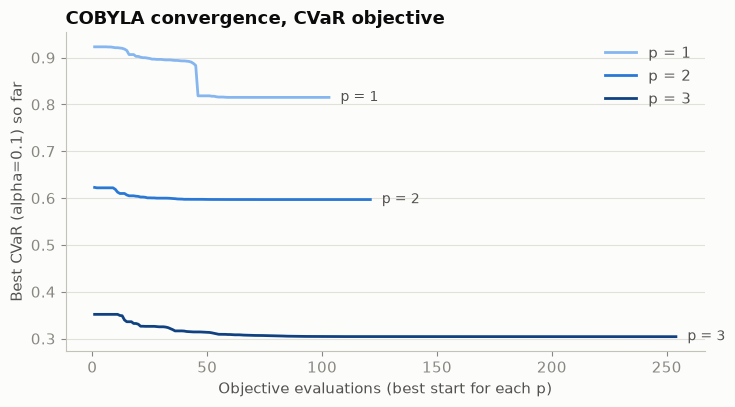

In [14]:
plots.plot_convergence(cvar_res[:3], "COBYLA convergence, CVaR objective");

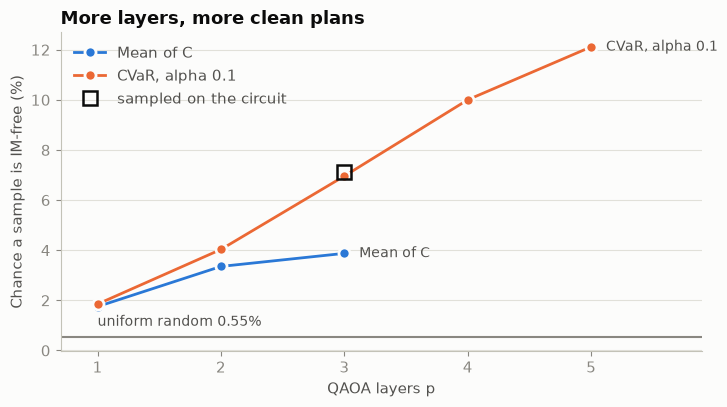

In [15]:
plots.plot_clean_vs_p({"Mean of C": mean_res, "CVaR, alpha 0.1": cvar_res}, fast.clean.mean(),
                      sampled=(3, plan.clean_share));

CVaR gives more IM-free samples, so `plan_mics` uses it with $p = 3$. Layers 4 and 5 ran only on the fast simulation, to keep this notebook quick. The mean objective stalls near 4%. The $p = 3$ CVaR angles here are the same ones `plan_mics` used in section 2, because both runs use the same seed:

In [16]:
best = cvar_res[2]
print("same angles as plan_mics:", np.allclose(best.gammas, plan.tuning[-1].gammas)
      and np.allclose(best.betas, plan.tuning[-1].betas))
print("gamma =", np.round(best.gammas, 4), " beta =", np.round(best.betas, 4))

same angles as plan_mics: True
gamma = [-0.6976 -1.0003 -1.1599]  beta = [0.3039 0.2512 0.1991]


**The real circuit at those angles.** `qaoa_ansatz` with the Dicke start and XY mixer, transpiled to `cx, rz, sx, x`, run as a Qiskit `Statevector` and compared with the fast simulation.

In [17]:
circ = quantum.compile_ansatz(quantum.build_ansatz(H_C, 5, reps=3))
agree = quantum.compare_with_circuit(fast, circ, best.gammas, best.betas)
print(f"fidelity {agree['fidelity']:.12f}")
print(f"probability outside the 5-mic plans {agree['leakage']:.1e}")
print(f"largest probability difference {agree['max_prob_diff']:.1e}  ({agree['seconds']:.0f} s for the statevector run)")

fidelity 1.000000000000
probability outside the 5-mic plans -6.9e-14
largest probability difference 3.0e-16  (18 s for the statevector run)


**The samples.** `plan_mics` drew 8,000 shots from `StatevectorSampler`. The most common ones:

In [18]:
top = sorted(plan.counts.items(), key=lambda kv: -kv[1])[:8]
for m, c in top:
    idx = engine.mask_to_indices(m)
    print(f"{c:4d} shots  {', '.join(f'{inst.freqs[i] / 1e6:.2f}' for i in idx)} MHz  "
          f"conflicting sets: {engine.cost_of(inst, idx):.0f}")
print(f"\nIM-free samples: {plan.clean_share:.2%} (exact {best.clean_prob:.2%}), uniform random {plan.random_share:.2%}")

  40 shots  470.00, 470.50, 471.50, 472.75, 473.50 MHz  conflicting sets: 0
  37 shots  470.00, 471.50, 472.00, 472.75, 473.75 MHz  conflicting sets: 0
  34 shots  470.00, 471.00, 472.50, 473.25, 473.75 MHz  conflicting sets: 0
  33 shots  470.25, 471.00, 472.00, 472.50, 473.25 MHz  conflicting sets: 1
  32 shots  470.50, 471.25, 471.75, 472.75, 473.50 MHz  conflicting sets: 1
  29 shots  470.00, 470.50, 471.50, 472.25, 473.50 MHz  conflicting sets: 0
  29 shots  470.00, 471.50, 472.50, 473.25, 473.75 MHz  conflicting sets: 0
  29 shots  470.00, 470.75, 471.25, 472.75, 473.75 MHz  conflicting sets: 0

IM-free samples: 7.11% (exact 6.96%), uniform random 0.55%


## 6. Results against classical baselines

Every classical method below solves this instance at once. That is expected with 16 frequencies.

In [19]:
rows = [baselines.run_brute_force(inst), baselines.greedy(inst), baselines.simulated_annealing(inst)["result"],
        baselines.uniform_random(inst)["result"], baselines.milp_solve(inst)]
clean_starts, _ = baselines.greedy_all_starts(inst)
fmt = lambda idx: ", ".join(f"{inst.freqs[i] / 1e6:.2f}" for i in idx)
table = ["| Method | Plan (MHz) | IM-free | Time | Note |", "|---|---|---|---|---|"]
for r in rows:
    table.append(f"| {r.name} | {fmt(r.plan)} | {'yes' if r.clean else 'no'} | {r.seconds * 1e3:.1f} ms | {r.note} |")
table.append(f"| QAOA, p = 3, CVaR (this work) | {fmt(plan.plan_indices)} | {'yes' if plan.clean else 'no'} | "
             f"{plan.seconds['total']:.0f} s | {plan.clean_share:.1%} of 8,000 samples IM-free |")
display(Markdown("\n".join(table)))
print(f"Greedy from each of the {inst.n_points} starting points ends clean {clean_starts} times.")

| Method | Plan (MHz) | IM-free | Time | Note |
|---|---|---|---|---|
| Brute force (exact) | 470.00, 470.50, 471.25, 472.25, 473.75 | yes | 10.7 ms | 24 of 4368 plans are IM-free |
| Greedy | 470.00, 470.50, 471.25, 472.25, 473.75 | yes | 1.2 ms |  |
| Simulated annealing | 470.00, 470.50, 471.50, 472.75, 473.50 | yes | 61.0 ms | 50 of 50 runs ended clean |
| Uniform random | 470.00, 470.50, 471.50, 472.25, 473.50 | yes | 57.0 ms | 0.50% of 8000 random plans are IM-free |
| Integer program (SciPy milp) | 470.00, 470.50, 471.25, 472.25, 473.75 | yes | 91.7 ms | Optimization terminated successfully. (HiGHS Status 7: Optimal) |
| QAOA, p = 3, CVaR (this work) | 470.00, 470.50, 471.50, 472.75, 473.50 | yes | 31 s | 7.1% of 8,000 samples IM-free |

Greedy from each of the 16 starting points ends clean 8 times.


**QAOA against random.** The histogram compares the QAOA samples with the exact spread over all 4,368 plans, which is what the Dicke start alone would give.

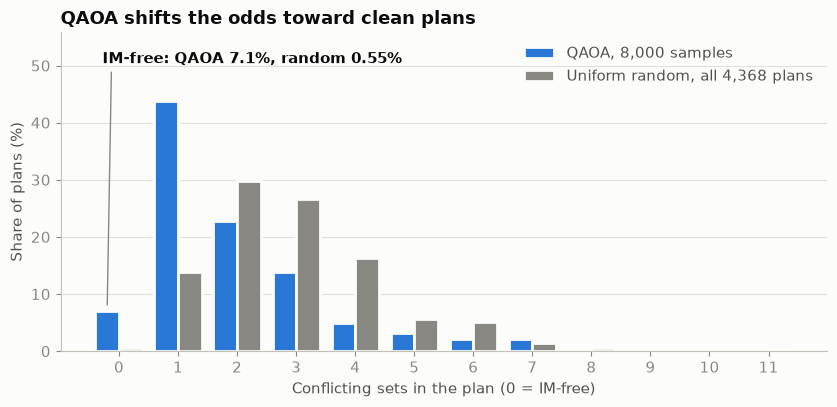

In [20]:
q_costs = [engine.cost_of(inst, engine.mask_to_indices(m)) for m in plan.counts]
q_w = np.array(list(plan.counts.values())) / plan.shots
plots.plot_histogram(q_costs, q_w, fast.cost, np.full(fast.dim, 1 / fast.dim),
                     labels=("QAOA, 8,000 samples", "Uniform random, all 4,368 plans"));

**What a newcomer might do.** Greedy is not our bad example, because greedy solves this instance (see the table). A person without software might instead space the mics evenly. That is the worst case: evenly spaced carriers are full of arithmetic progressions, and every progression puts a product right on a mic. The checker lists each hit.

20 problems: 0 spacing, 8 two-tone hits, 12 three-tone hits
  two-tone: 2 x 470.750 MHz - 470.000 MHz = 471.500 MHz, right on the mic at 471.500 MHz
  two-tone: 2 x 470.750 MHz - 471.500 MHz = 470.000 MHz, right on the mic at 470.000 MHz
  two-tone: 2 x 471.500 MHz - 470.000 MHz = 473.000 MHz, right on the mic at 473.000 MHz
  two-tone: 2 x 471.500 MHz - 470.750 MHz = 472.250 MHz, right on the mic at 472.250 MHz
  two-tone: 2 x 471.500 MHz - 472.250 MHz = 470.750 MHz, right on the mic at 470.750 MHz
  two-tone: 2 x 471.500 MHz - 473.000 MHz = 470.000 MHz, right on the mic at 470.000 MHz
  two-tone: 2 x 472.250 MHz - 471.500 MHz = 473.000 MHz, right on the mic at 473.000 MHz
  two-tone: 2 x 472.250 MHz - 473.000 MHz = 471.500 MHz, right on the mic at 471.500 MHz
  three-tone: 470.000 MHz + 472.250 MHz - 470.750 MHz = 471.500 MHz, right on the mic at 471.500 MHz
  three-tone: 470.000 MHz + 472.250 MHz - 471.500 MHz = 470.750 MHz, right on the mic at 470.750 MHz
  three-tone: 470.000 MHz 

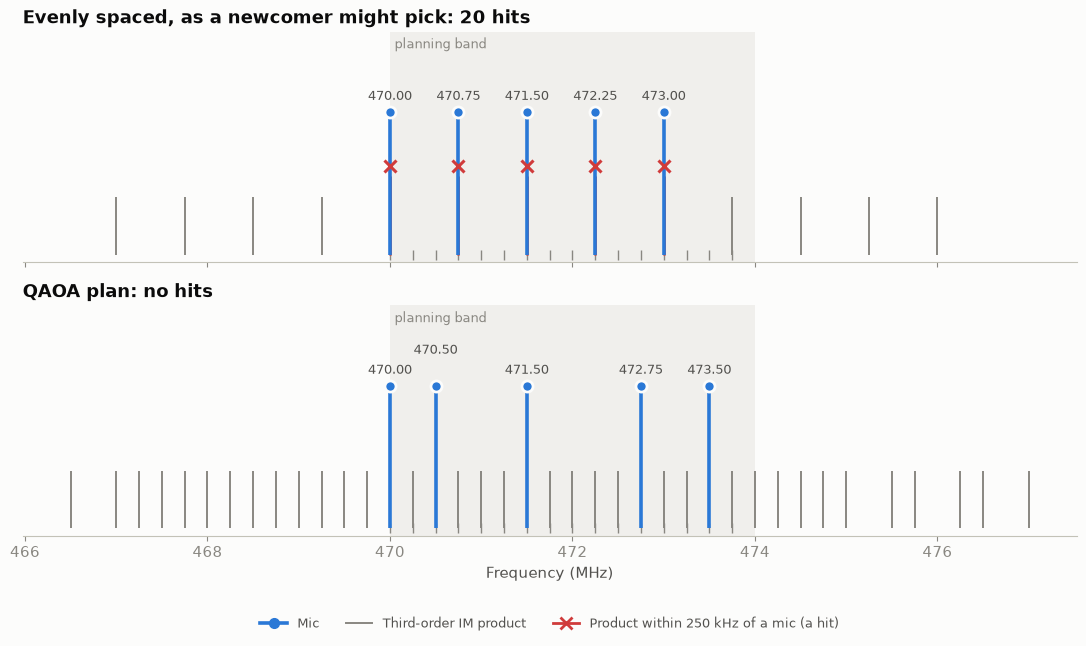

In [21]:
newcomer = (0, 3, 6, 9, 12)
nc = engine.check_indices(inst, newcomer)
print(nc.report())
hz = lambda idx: [inst.freqs[i] for i in idx]
plots.plot_side_by_side((hz(newcomer), f"Evenly spaced, as a newcomer might pick: {len(nc.violations)} hits"),
                        (hz(plan.plan_indices), "QAOA plan: no hits"), inst.spacing, inst.im_guard,
                        band=inst.band, grid=inst.freqs);

## 7. Resource card

Gate counts after transpiling to `cx, rz, sx, x` (optimization level 1, all-to-all connectivity), and the size of the same problem written as a QUBO.

In [22]:
card = quantum.resource_card(H_C, n_mics=5, reps=3)
qs = cost.qubo_size(inst)
zs = card["z_strings"]
rows = [("Qubits", f"{card['qubits']}"),
        ("Z-strings by weight 1 / 2 / 3 / 4", " / ".join(str(zs[w]) for w in (1, 2, 3, 4)) + f" ({sum(zs.values())} in all)"),
        ("Dicke start", f"{card['dicke']['cx']:,} CNOTs"),
        ("One cost layer, as built by qaoa_ansatz", f"{card['cost_layer']['cx']:,} CNOTs "
         f"(naive ladder count {card['cost_layer_naive_cx']:,}; {card['cost_layer_single_gate']['cx']:,} "
         "if synthesized as one PauliEvolutionGate)"),
        ("One XY mixer layer", f"{card['mixer_layer']['cx']} CNOTs"),
        ("Full circuit, p = 3", f"{card['full']['cx']:,} CNOTs, depth {card['full']['depth']:,}"),
        ("Transpile time, full circuit", f"{card['full']['transpile_s']:.2f} s"),
        ("Statevector run, full circuit", f"{agree['seconds']:.0f} s"),
        ("Same problem as a QUBO", f"{qs['variables']} binary variables (greedy Rosenberg; "
         f"{qs['best_variables']} to {qs['worst_variables']} over {qs['trials']} tie-break orders)")]
display(Markdown("| Item | Value |\n|---|---|\n" + "\n".join(f"| {a} | {b} |" for a, b in rows)))
print(f"{qs['qubits']} qubits here vs {qs['variables']} variables as a QUBO")

| Item | Value |
|---|---|
| Qubits | 16 |
| Z-strings by weight 1 / 2 / 3 / 4 | 16 / 120 / 560 / 252 (948 in all) |
| Dicke start | 560 CNOTs |
| One cost layer, as built by qaoa_ansatz | 4,006 CNOTs (naive ladder count 3,992; 2,570 if synthesized as one PauliEvolutionGate) |
| One XY mixer layer | 46 CNOTs |
| Full circuit, p = 3 | 12,716 CNOTs, depth 12,076 |
| Transpile time, full circuit | 0.12 s |
| Statevector run, full circuit | 18 s |
| Same problem as a QUBO | 121 binary variables (greedy Rosenberg; 114 to 125 over 200 tie-break orders) |

16 qubits here vs 121 variables as a QUBO


**Why the QUBO is bigger.** A QUBO allows only pairs of variables. Each triple or quadruple term needs auxiliary variables $y = x_i x_j$, held in place by Rosenberg penalty terms [13]. We count them greedily: replace the pair that appears in the most high-degree terms, and repeat until every term has two variables or fewer. A QUBO would also need a penalty to hold the mic count at 5.

**The other side of the trade.** The gate model pays in depth instead: about 4,000 CNOTs per cost layer and 12,716 for the whole $p = 3$ circuit. We have not run it on hardware, and we expect a circuit this deep to be dominated by noise on current devices.

## 8. Where it falls short

- **No speed-up.** QAOA is a heuristic with no proven advantage here, and we claim none.
- **Classically trivial at this size.** Brute force takes about 10 ms. Greedy solves it, and simulated annealing ends clean in 50 of 50 runs.
- **A modest gain over random.** At $p = 3$, 7.1% of samples are IM-free against 0.55% for random plans, about 13 times better. On the fast simulation, $p = 5$ reaches 12%. The angles were tuned by exact classical simulation, which is impossible at large sizes.
- **It is a Golomb-ruler search here.** With exact landings on a uniform grid, IM-free plans are Golomb rulers with no gap of 1, a connection known since 1953 [14].
- **A guard model simpler than a coordinator's.** Third-order products only (Shure also lists fifth-order ones [1]). No TV channel data, transmitter power, distance or receiver selectivity. A uniform grid, and every carrier treated alike.
- **Venue facts.** The band and the exclusion are illustrative, not the theatre's real setup.
- **Free vendor tools exist.** Shure's Wireless Workbench is free [15] and far more complete. Our contribution is a quantum route that models IM, behind a plain-English interface, not a replacement for those tools.

**Beyond the toy size.** Six IM-free mics with these rules need 21 grid points, and only two plans work:

In [23]:
six = engine.build_instance("470-475.25 MHz", mics=6)
bf6 = engine.brute_force(six)
print(f"6 mics: {six.n_points} points ({six.n_points} qubits), {bf6.n_plans:,} plans, {bf6.n_clean} IM-free:",
      [[f"{six.freqs[i] / 1e6:.2f}" for i in p] for p in bf6.best_plans])

6 mics: 21 points (21 qubits), 54,264 plans, 2 IM-free: [['470.00', '470.50', '472.00', '473.25', '474.25', '475.00'], ['470.00', '470.75', '471.75', '473.00', '474.50', '475.00']]


For 40 mics on this kind of grid, the 780 pairwise differences must be distinct and at least 2, so the largest is at least 781. The grid then needs at least 782 points, which is 782 qubits and about 195 MHz at 250 kHz steps. The number of conflicting sets on such a grid:

In [24]:
N40 = 782
T40, Q40 = engine.uniform_grid_term_counts(N40)
print(f"{N40} qubits: {T40:,} triple terms and {Q40:,} quadruple terms")
print(f"for comparison, 16 points: {engine.uniform_grid_term_counts(16)}")

782 qubits: 152,490 triple terms and 39,621,985 quadruple terms
for comparison, 16 points: (56, 252)


That is tens of millions of four-body terms in every cost layer. A real system would also work off-grid, with finer tuning steps and several bands. A practical quantum route at that size would need a much sparser model, problem decomposition, or both. That is open work.

## 9. References

1. Shure, "All about wireless intermodulation distortion". https://www.shure.com/en-US/insights/all-about-wireless-intermodulation-distortion
2. SoundPro, "RF coordination for live events" (2026 guide). https://soundpro.com/blogs/live-production/rf-coordination-live-events-guide-2026
3. University of Waterloo Theatres, "Our theatres". https://uwaterloo.ca/theatres/venue-rental/our-theatres
4. University of Waterloo Theatres, "Humanities Theatre technical specs". https://uwaterloo.ca/theatres/venue-rental/humanities-theatre/humanities-theatre-technical-specs
5. D-Wave, frequency-selection example. https://github.com/dwave-examples/frequency-selection
6. M. Vandelli, F. Ferrari, D. Dragoni, "Constraint-preserving quantum algorithm for the multi-frequency antenna placement problem", arXiv:2511.15566 (2025).
7. E. Farhi, J. Goldstone, S. Gutmann, "A Quantum Approximate Optimization Algorithm", arXiv:1411.4028 (2014).
8. A. Bärtschi, S. Eidenbenz, "Deterministic Preparation of Dicke States", arXiv:1904.07358 (2019).
9. S. Hadfield et al., "From the Quantum Approximate Optimization Algorithm to a Quantum Alternating Operator Ansatz", Algorithms 12(2), 34 (2019), arXiv:1709.03489.
10. Z. Wang, N. C. Rubin, J. M. Dominy, E. G. Rieffel, "XY-mixers: analytical and numerical results for QAOA", Phys. Rev. A 101, 012320 (2020), arXiv:1904.09314.
11. P. Kl. Barkoutsos et al., "Improving Variational Quantum Optimization using CVaR", Quantum 4, 256 (2020), arXiv:1907.04769.
12. L. Zhou et al., "Quantum Approximate Optimization Algorithm: Performance, Mechanism, and Implementation on Near-Term Devices", Phys. Rev. X 10, 021067 (2020), arXiv:1812.01041.
13. I. G. Rosenberg, "Reduction of bivalent maximization to the quadratic case", Cahiers du Centre d'Études de Recherche Opérationnelle 17, 71 to 74 (1975).
14. W. C. Babcock, "Intermodulation Interference in Radio Systems", Bell System Technical Journal 32, 63 to 73 (1953), doi:10.1002/j.1538-7305.1953.tb01422.x.
15. Shure, "Wireless Workbench". https://shure.com/en-us/products/software/wwb
16. A. Javadi-Abhari et al., "Quantum computing with Qiskit", arXiv:2405.08810 (2024).

In [25]:
print(f"Notebook runtime: {time.perf_counter() - T0:.0f} s")

Notebook runtime: 109 s
